# 14. Medición de desempeño de metaheurísticas

**Serie:** metaheurísticas from scratch · Bloque 05 — Evaluación y ajuste

Anterior: [13 · Métodos híbridos y paralelos](../04-topicos-avanzados/13-metodos-hibridos-y-paralelos.ipynb) ·
Siguiente: [15 · Ajuste de parámetros](15-ajuste-de-parametros.ipynb)

---

## Contenido

1. Por qué evaluar metaheurísticas es difícil
2. Banco de pruebas: generación de instancias (tipos y tamaños)
3. Tres algoritmos compactos sobre TSP: SA, GA y ACO
4. Diseño experimental: repeticiones, semillas y presupuesto
5. Métricas de calidad: gap relativo, desviación vs mejor conocido, ranking
6. Consistencia: varianza, boxplots y tasa de éxito
7. Tiempo de ejecución, tasa de crecimiento y soluciones por segundo
8. Presupuesto en evaluaciones vs presupuesto en tiempo
9. Perfiles de desempeño de Dolan–Moré
10. Curvas de tiempo-hasta-el-objetivo (ECDF / run-length distributions)
11. Pruebas estadísticas: Wilcoxon, Friedman + Nemenyi/Holm, tamaño de efecto
12. Cuántas repeticiones necesito
13. Lista de verificación, resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Qué vas a aprender**

- A construir un banco de pruebas sintético y justo, con instancias de distinto tipo y tamaño.
- A diseñar un experimento para algoritmos **estocásticos**: repeticiones independientes, semillas, presupuesto.
- A resumir resultados con métricas de calidad, consistencia y costo, y a *visualizarlos* con boxplots, perfiles de
  desempeño y distribuciones de tiempo-hasta-el-objetivo.
- A decidir si la diferencia entre dos algoritmos es **estadísticamente creíble** y si es **grande**.

**Prerrequisitos**

- Haber visto TSP y vecindarios 2-opt ([02](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb),
  [03](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb)), recocido simulado
  ([05](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb)), colonia de hormigas
  ([08](../02-metodos-con-memoria/08-colonia-de-hormigas.ipynb)) y algoritmos genéticos
  ([09](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb)). Aquí escribimos versiones **compactas** de cada uno,
  así que la notebook es autocontenida.
- Estadística básica: media, mediana, intervalos de confianza, pruebas de hipótesis.

In [1]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

rng_global = np.random.default_rng(14)      # semilla maestra de la notebook
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Por qué evaluar metaheurísticas es difícil

Un algoritmo exacto se juzga por **correctitud y complejidad**. Una metaheurística se juzga por *qué tan buenas son las
soluciones que entrega en un presupuesto dado*, y esa cantidad es una **variable aleatoria**: depende de la instancia, de la
semilla y de cuánto cómputo se le deja usar. Evaluar bien es un problema de **inferencia estadística sobre experimentos
computacionales** (Barr et al., 1995; Johnson, 2002; McGeoch, 2012).

Errores típicos que el diseño de esta notebook intenta evitar:

| Error común | Consecuencia | Remedio que veremos |
|---|---|---|
| Reportar una sola corrida | Se confunde suerte con calidad | Repeticiones independientes (secc. 4) |
| Reportar solo el mejor resultado | Sesgo hacia el máximo de una distribución | Media/mediana, dispersión, tasa de éxito (secc. 5-6) |
| Comparar con presupuestos distintos | Gana quien más cómputo usa | Presupuesto común (secc. 4, 8) |
| Probar con una sola instancia | No generaliza | Banco de pruebas variado (secc. 2) |
| Ajustar parámetros de un método y dejar los otros por defecto | Comparación injusta | Misma política de ajuste ([notebook 15](15-ajuste-de-parametros.ipynb)) |
| Comparar con "p < 0.05" sin tamaño de efecto | Diferencias reales pero irrelevantes | Tamaño de efecto (secc. 11) |
| Ignorar que muchas pruebas inflan falsos positivos | Hallazgos espurios | Corrección de Holm (secc. 11) |

## 2. Banco de pruebas: generación de instancias

Un **banco de pruebas** (*benchmark*) debe cubrir factores que se sabe que afectan la dificultad. Para el TSP euclídeo
usaremos dos ejes:

- **Tipo de estructura** (cambia la forma del paisaje de búsqueda):
  - `uniforme`: puntos uniformes en $[0,1]^2$ (el caso "estándar" de la literatura).
  - `agrupada`: mezcla de gaussianas (clusters); hay pocas aristas largas "obligatorias" y muchas cortas casi equivalentes.
  - `rejilla`: puntos sobre una malla con ruido; produce **muchos empates casi exactos** (mesetas), difíciles para
    reglas voraces.
- **Tamaño** $n$: para el estudio de calidad usamos $n\in\{25,50\}$ y para el estudio de escalamiento llegaremos a $n=150$.

Cada instancia se genera con una semilla propia, por lo que el banco es **reproducible** y extensible sin tocar el resto del
código. Además definimos un verificador de permutaciones: **toda solución que reporte un algoritmo se valida** antes de
contarla.

In [2]:
from scipy.spatial.distance import cdist

def generar_instancia(n, tipo, rng):
    """Genera una instancia euclídea. tipo: 'uniforme', 'agrupada' o 'rejilla'."""
    if tipo == "uniforme":
        pts = rng.random((n, 2))
    elif tipo == "agrupada":
        k = max(3, n // 10)
        centros = rng.random((k, 2))
        asign = rng.integers(0, k, n)
        pts = centros[asign] + 0.04 * rng.standard_normal((n, 2))
    elif tipo == "rejilla":
        m = int(np.ceil(np.sqrt(n)))
        g = np.array([(i, j) for i in range(m) for j in range(m)], float) / m
        pts = g[rng.permutation(len(g))[:n]] + 0.1 / m * rng.standard_normal((n, 2))
    else:
        raise ValueError(tipo)
    return pts, cdist(pts, pts)

def largo_tour(D, t):
    """Largo del ciclo; t es una permutación (1D) o un lote de permutaciones (2D)."""
    t = np.asarray(t)
    return D[t, np.roll(t, -1, axis=-1)].sum(axis=-1)

def es_permutacion(t, n):
    return len(t) == n and np.array_equal(np.sort(np.asarray(t)), np.arange(n))

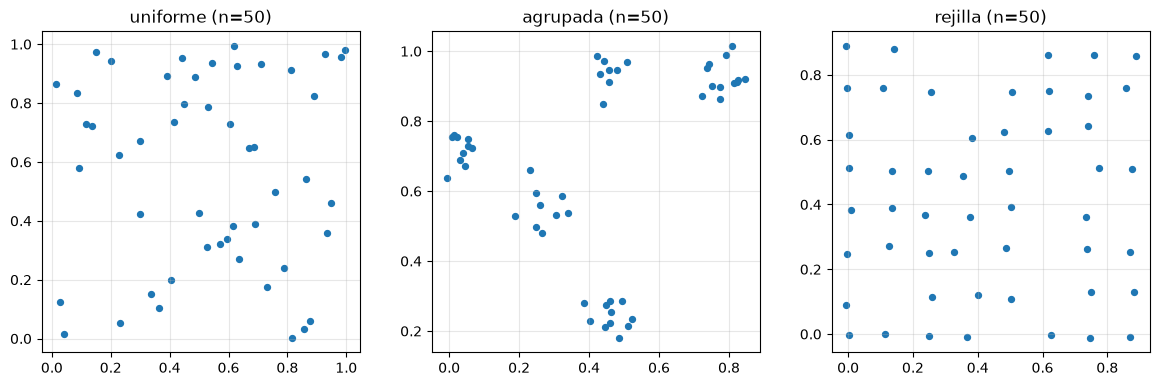

In [3]:
# Verificación de utilidades y vista del banco
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, tipo in zip(axs, ["uniforme", "agrupada", "rejilla"]):
    pts, D = generar_instancia(50, tipo, rng)
    assert np.allclose(D, D.T) and np.allclose(np.diag(D), 0)
    ax.scatter(pts[:, 0], pts[:, 1], s=18); ax.set_title(f"{tipo} (n=50)"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [4]:
# Banco: 3 tipos x 2 tamaños x 2 instancias = 12 instancias
BANCO = []
for tipo in ["uniforme", "agrupada", "rejilla"]:
    for n in [25, 50]:
        for k in range(2):
            rng_i = np.random.default_rng([14, n, k, ["uniforme", "agrupada", "rejilla"].index(tipo)])
            pts, D = generar_instancia(n, tipo, rng_i)
            BANCO.append(dict(id=len(BANCO), tipo=tipo, n=n, k=k, pts=pts, D=D))
print(pd.DataFrame([{c: b[c] for c in ("id", "tipo", "n", "k")} for b in BANCO]).T.to_string())

            0         1         2         3         4         5         6         7        8        9        10       11
id           0         1         2         3         4         5         6         7        8        9       10       11
tipo  uniforme  uniforme  uniforme  uniforme  agrupada  agrupada  agrupada  agrupada  rejilla  rejilla  rejilla  rejilla
n           25        25        50        50        25        25        50        50       25       25       50       50
k            0         1         0         1         0         1         0         1        0        1        0        1


## 3. Tres algoritmos compactos sobre TSP

Escribimos versiones **mínimas pero correctas** de tres metaheurísticas. El objetivo no es ganar un concurso, sino tener
tres métodos de naturaleza distinta (trayectoria, constructivo con memoria, poblacional) para compararlos con rigor.

| Método | Familia | Idea compacta | Costo por evaluación |
|---|---|---|---|
| **SA** | trayectoria | vecindario 2-opt, aceptación de Metropolis, enfriamiento geométrico | **$O(1)$** (se evalúa el *delta*) |
| **ACO** (tipo MAX-MIN) | constructivo + memoria | hormigas construyen tours con $\tau^\alpha\eta^\beta$; solo refuerza la mejor de la iteración | $O(n)$ (tour completo) |
| **GA** | poblacional | torneo, cruce OX simplificado, mutación por reversión, elitismo | $O(n)$ (tour completo) |

**Cuidado con "evaluación".** En SA con 2-opt, una evaluación es $\Delta = d_{ac}+d_{bd}-d_{ab}-d_{cd}$ y cuesta $O(1)$; en
GA/ACO se calcula el largo completo, $O(n)$. Por eso el *número de evaluaciones* no es una unidad de cómputo equivalente
entre algoritmos: lo discutiremos en la sección 8 y mostraremos las dos comparaciones.

Todos los algoritmos devuelven `(mejor_largo, mejor_tour, traza, n_evaluaciones)`, donde `traza[e]` es el mejor valor
encontrado tras `e+1` evaluaciones (curva *anytime*). Esa traza es la materia prima de los perfiles y las ECDF.

In [5]:
import time

def _rellenar(trace, ini, largos, mejor):
    """Escribe en trace[ini:ini+len(largos)] el mejor-hasta-ahora tras cada evaluación del lote."""
    acum = np.minimum.accumulate(np.minimum(largos, mejor))
    trace[ini:ini + len(largos)] = acum
    return acum[-1]

def sa_tsp(D, presupuesto, rng, t0f=0.1, tendf=0.002, tmax=None, traza=True):
    """Recocido simulado con vecindario 2-opt (delta O(1)). Cada movimiento propuesto = 1 evaluación.
    La temperatura baja geométricamente de t0f*escala a tendf*escala según el avance
    (evaluaciones consumidas, o tiempo transcurrido si se da tmax)."""
    n = len(D); Dl = D.tolist(); escala = D.sum() / (n * (n - 1))
    T0, Tf = t0f * escala, tendf * escala
    t = list(rng.permutation(n)); L = float(largo_tour(D, t)); mejor, mejor_t = L, t[:]
    I = rng.integers(0, n, size=(presupuesto, 2)); U = rng.random(presupuesto)
    tr = np.empty(presupuesto) if (traza and tmax is None) else None
    t_ini = time.perf_counter(); e = 0; T = T0
    while True:
        if e % 64 == 0:
            frac = e / presupuesto if tmax is None else (time.perf_counter() - t_ini) / tmax
            if frac >= 1: break
            T = T0 * (Tf / T0) ** frac
        if e >= presupuesto: break           # (en modo tiempo el arreglo I se agotaría antes; ver abajo)
        i, j = I[e]
        if i > j: i, j = j, i
        if i != j and not (i == 0 and j == n - 1):
            a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % n]
            delta = Dl[a][c] + Dl[b][d] - Dl[a][b] - Dl[c][d]
            if delta < 0 or U[e] < np.exp(-delta / T):
                t[i:j + 1] = t[i:j + 1][::-1]; L += delta
                if L < mejor - 1e-12: mejor, mejor_t = L, t[:]
        if tr is not None: tr[e] = mejor
        e += 1
    return mejor, np.array(mejor_t), tr, e

def ga_tsp(D, presupuesto, rng, pob=40, pc=0.9, pm=0.3, k=3, tmax=None, traza=True):
    """AG generacional con torneo, cruce OX simplificado y mutación por reversión de segmento
    (elitismo de 1). Cada hijo evaluado = 1 evaluación (costo O(n))."""
    n = len(D)
    P = np.array([rng.permutation(n) for _ in range(pob)]); F = largo_tour(D, P)
    tr = np.empty(presupuesto) if (traza and tmax is None) else None
    e = pob; mejor = F.min()
    if tr is not None: _rellenar(tr, 0, F[:min(pob, presupuesto)], np.inf)
    t_ini = time.perf_counter()
    while e < presupuesto and (tmax is None or time.perf_counter() - t_ini < tmax):
        nh = min(pob - 1, presupuesto - e)
        H = np.empty((nh, n), dtype=int)
        for h in range(nh):
            ia = rng.integers(0, pob, k); ib = rng.integers(0, pob, k)
            p1, p2 = P[ia[F[ia].argmin()]], P[ib[F[ib].argmin()]]
            if rng.random() < pc:
                a, b = np.sort(rng.integers(0, n + 1, 2)); seg = p1[a:b]
                resto = p2[~np.isin(p2, seg)]
                hijo = np.concatenate([resto[:a], seg, resto[a:]])
            else:
                hijo = p1.copy()
            if rng.random() < pm:
                a, b = np.sort(rng.integers(0, n, 2)); hijo[a:b + 1] = hijo[a:b + 1][::-1]
            H[h] = hijo
        FH = largo_tour(D, H)
        if tr is not None: mejor = _rellenar(tr, e, FH, mejor)
        e += nh
        elite = P[F.argmin()].copy(); fe = F.min()
        P = np.vstack([elite, H]); F = np.concatenate([[fe], FH]); mejor = min(mejor, F.min())
    return F.min(), P[F.argmin()], tr, e

def aco_tsp(D, presupuesto, rng, m=20, alpha=1.0, beta=3.0, rho=0.1, tmax=None, traza=True):
    """ACO tipo MAX-MIN Ant System: m hormigas construyen en paralelo (vectorizado), refuerza solo
    la mejor de la iteración, feromona acotada en [tau_min, tau_max]. Cada tour = 1 evaluación."""
    n = len(D); eta = 1.0 / (D + np.eye(n))
    # cota inicial: largo de un tour vecino-más-cercano
    L0 = largo_tour(D, _nn(D, 0)); tau_max = 1.0 / (rho * L0); tau = np.full((n, n), tau_max)
    tr = np.empty(presupuesto) if (traza and tmax is None) else None
    mejor, mejor_t, e = np.inf, None, 0; t_ini = time.perf_counter(); ar = np.arange(m)
    while e < presupuesto and (tmax is None or time.perf_counter() - t_ini < tmax):
        W = (tau ** alpha) * (eta ** beta)
        nm = min(m, presupuesto - e)
        T = np.empty((nm, n), dtype=int); T[:, 0] = rng.integers(0, n, nm)
        vis = np.ones((nm, n), bool); vis[np.arange(nm), T[:, 0]] = False
        for s in range(1, n):
            w = W[T[:, s - 1]] * vis
            cs = np.cumsum(w, axis=1); r = rng.random(nm) * cs[:, -1]
            nx = np.minimum((cs < r[:, None]).sum(1), n - 1)
            nx = np.where(vis[np.arange(nm), nx], nx, w.argmax(1))   # salvaguarda numérica
            T[:, s] = nx; vis[np.arange(nm), nx] = False
        Ls = largo_tour(D, T)
        if tr is not None: _rellenar(tr, e, Ls, mejor)
        e += nm; ib = Ls.argmin()
        if Ls[ib] < mejor: mejor, mejor_t = Ls[ib], T[ib].copy()
        tau *= (1 - rho)
        a_, b_ = T[ib], np.roll(T[ib], -1)
        tau[a_, b_] += 1.0 / Ls[ib]; tau[b_, a_] += 1.0 / Ls[ib]
        tau_max = 1.0 / (rho * mejor); tau_min = tau_max / (2 * n)
        np.clip(tau, tau_min, tau_max, out=tau)
    return mejor, mejor_t, tr, e

def _nn(D, s):
    n = len(D); vis = np.zeros(n, bool); t = [s]; vis[s] = True
    for _ in range(n - 1):
        d = np.where(vis, np.inf, D[t[-1]]); j = int(d.argmin()); t.append(j); vis[j] = True
    return np.array(t)

In [6]:
# Validación de correctitud: tours son permutaciones, el largo reportado coincide con el recomputado,
# el delta 2-opt coincide con la recomputación completa.
pts, D = generar_instancia(30, "uniforme", np.random.default_rng(5))
for f in (sa_tsp, ga_tsp, aco_tsp):
    L, t, tr, ev = f(D, 3000, np.random.default_rng(1))
    assert es_permutacion(t, 30), f.__name__
    assert abs(largo_tour(D, t) - L) < 1e-9, f.__name__
    assert ev == 3000 and np.all(np.diff(tr) <= 1e-12) and abs(tr[-1] - L) < 1e-9   # traza monótona no creciente
    print(f"{f.__name__:8s} OK  L={L:.4f}  evals={ev}")

t = list(np.random.default_rng(2).permutation(30)); i, j = 4, 17
a, b, c, d = t[i - 1], t[i], t[j], t[(j + 1) % 30]
delta = D[a, c] + D[b, d] - D[a, b] - D[c, d]
t2 = t[:i] + t[i:j + 1][::-1] + t[j + 1:]
print("delta 2-opt vs recomputación completa:", round(delta, 12), round(largo_tour(D, t2) - largo_tour(D, t), 12))

sa_tsp   OK  L=4.6488  evals=3000
ga_tsp   OK  L=5.6480  evals=3000
aco_tsp  OK  L=4.3933  evals=3000
delta 2-opt vs recomputación completa: 0.09816854058 0.09816854058


## 4. Diseño experimental para metaheurísticas

### 4.1 Repeticiones independientes y semillas

Para una instancia $p$ y un algoritmo $s$, el resultado de una corrida es $X_{p,s}(\omega)$ con $\omega$ la semilla. Para
estimar $\mathbb E[X_{p,s}]$, la mediana, la cola, etc., necesitamos **$R$ corridas independientes**. Buenas prácticas:

- Un generador **independiente por corrida**: usamos `np.random.SeedSequence(entropia, spawn_key=(instancia, algoritmo, rep))`,
  que garantiza flujos estadísticamente independientes aunque las semillas "se parezcan". Sumar 1 a una semilla entera
  *no* es la forma recomendada.
- Semillas **registradas**: cualquier corrida se puede reproducir.
- **Ni la instancia ni el orden de ejecución** pueden depender de los resultados.
- La unidad de análisis en las pruebas estadísticas es la **instancia** (con una medida resumen de sus repeticiones), no la
  corrida, a menos que se modele explícitamente el efecto de instancia (ver [notebook 15](15-ajuste-de-parametros.ipynb)).
  Las corridas de una misma instancia son réplicas, no instancias distintas: tratarlas como independientes de instancias
  es *pseudo-replicación*.

### 4.2 Presupuesto: evaluaciones vs. tiempo

| Presupuesto | Ventajas | Desventajas |
|---|---|---|
| **Evaluaciones** de la función objetivo | Independiente de la máquina y del lenguaje; reproducible exactamente | Ignora el costo del resto del algoritmo (el operador, la memoria, el $O(1)$ vs $O(n)$ del delta) |
| **Tiempo** de reloj (CPU) | Refleja el costo real de uso | Depende de hardware, carga, implementación; ruidoso |

La recomendación habitual es reportar **ambos** o usar evaluaciones como presupuesto principal y tiempo como
complemento. Aquí: presupuesto principal de $B=10\,000$ evaluaciones por corrida, y una comparación a tiempo fijo en la sección 8.

### 4.3 Mejor conocido

Para medir calidad necesitamos una referencia $L^\ast_p$. Para instancias aleatorias pequeñas no tenemos el óptimo exacto, así
que usamos el **mejor conocido** (*best known solution*, BKS): el mínimo sobre **todas** las corridas del estudio más
algunas corridas largas de SA con presupuesto 20 veces mayor. Es una cota superior del óptimo, por lo que el gap
reportado es **una cota inferior del gap real** y puede ser 0 para el método que encuentre el BKS. Hay que decirlo
explícitamente al reportar resultados.

In [7]:
PRESUPUESTO = 10_000      # evaluaciones por corrida
REPS = 12                 # repeticiones independientes por (instancia, algoritmo)
ALG = {"SA": sa_tsp, "GA": ga_tsp, "ACO": aco_tsp}
ENTROPIA = 20240614

def rng_corrida(inst_id, alg_idx, rep):
    # flujo independiente por corrida, reproducible
    return np.random.default_rng(np.random.SeedSequence(ENTROPIA, spawn_key=(inst_id, alg_idx, rep)))

# demostración: dos corridas del mismo algoritmo con distinta semilla dan distinto resultado; misma semilla, igual
D0 = BANCO[0]["D"]
print([round(sa_tsp(D0, 2000, rng_corrida(0, 0, r))[0], 4) for r in range(3)], "<- semillas 0,1,2")
print(round(sa_tsp(D0, 2000, rng_corrida(0, 0, 0))[0], 4), "<- semilla 0 de nuevo (reproducible)")

[4.5119, 4.2394, 4.3378] <- semillas 0,1,2
4.5119 <- semilla 0 de nuevo (reproducible)


In [8]:
# Experimento principal: 12 instancias x 3 algoritmos x 12 repeticiones
t_ini = time.perf_counter()
filas, TRAZAS = [], {}
for b in BANCO:
    for ai, (nom, f) in enumerate(ALG.items()):
        T = np.empty((REPS, PRESUPUESTO), dtype=np.float32)
        for r in range(REPS):
            t0 = time.perf_counter()
            L, tour, tr, ev = f(b["D"], PRESUPUESTO, rng_corrida(b["id"], ai, r))
            seg = time.perf_counter() - t0
            assert es_permutacion(tour, b["n"]) and abs(largo_tour(b["D"], tour) - L) < 1e-9
            T[r] = tr
            filas.append(dict(inst=b["id"], tipo=b["tipo"], n=b["n"], alg=nom, rep=r, L=L, seg=seg, evals=ev))
        TRAZAS[(b["id"], nom)] = T
df = pd.DataFrame(filas)
print(f"{len(df)} corridas en {time.perf_counter() - t_ini:.1f} s")

# BKS: mínimo del estudio y de corridas largas de SA (20x presupuesto)
bks = df.groupby("inst").L.min().to_dict()
for b in BANCO:
    for r in range(3):
        Lbig = sa_tsp(b["D"], 20 * PRESUPUESTO, np.random.default_rng(np.random.SeedSequence(ENTROPIA, spawn_key=(99, b["id"], r))))[0]
        bks[b["id"]] = min(bks[b["id"]], Lbig)
df["bks"] = df.inst.map(bks)
df["gap"] = 100 * (df.L - df.bks) / df.bks
print(df.head(3).round(4).to_string())

432 corridas en 107.0 s


   inst      tipo   n alg  rep       L     seg  evals     bks     gap
0     0  uniforme  25  SA    0  4.1358  0.0107  10000  4.1358  0.0000
1     0  uniforme  25  SA    1  4.1364  0.0106  10000  4.1358  0.0147
2     0  uniforme  25  SA    2  4.1358  0.0105  10000  4.1358  0.0000


## 5. Métricas de calidad de la solución

Sea $L_{p,s,r}$ el largo obtenido por el algoritmo $s$ en la instancia $p$, repetición $r$. Definimos:

- **Gap relativo** respecto al mejor conocido:
$$\mathrm{gap}_{p,s,r}=100\cdot\frac{L_{p,s,r}-L^\ast_p}{L^\ast_p}\ \ (\%).$$
  Es adimensional, por lo que **se puede promediar entre instancias de escala distinta** (el largo absoluto no).
- **Desviación vs. mejor conocido**: lo mismo en valor absoluto, útil cuando $L^\ast$ es cercano a 0 (aquí no).
- **Ranking** por instancia: ordenar algoritmos de 1 (mejor) a $k$ según una medida resumen (p. ej. mediana del gap); los
  empates reciben rango promedio. El ranking descarta la magnitud pero es robusto a escalas y base de las pruebas de
  Friedman (secc. 11).
- **Mejor / mediana / media / peor** de las repeticiones. Un solo número oculta la distribución; reportar siempre
  una medida de tendencia **y** una de dispersión.

Nota sobre **qué promediar**: la media del gap es sensible a corridas catastróficas; la mediana es robusta. Si el
algoritmo se usará **una sola vez** en producción, la media (o un cuantil alto) importa; si se usa con reinicios y
se queda con la mejor, importa la cola inferior (el *mejor de* $k$).

In [9]:
resumen = (df.groupby(["alg"]).gap.agg(media="mean", mediana="median", mejor="min", peor="max").round(3))
print("Gap relativo (%) global, pooled sobre instancias y repeticiones:")
print(resumen.to_string())

tab_tipo = df.pivot_table(index=["tipo", "n"], columns="alg", values="gap", aggfunc="median").round(3)
print("\nMediana del gap (%) por tipo y tamaño:")
print(tab_tipo.to_string())

# Ranking por instancia (según mediana del gap) y ranking medio
M = df.pivot_table(index="inst", columns="alg", values="gap", aggfunc="median")[["SA", "GA", "ACO"]]
RANGOS = M.rank(axis=1)
print("\nRanking medio (1 = mejor), N =", len(M), "instancias:")
print(RANGOS.mean().round(3).to_string())
print("\nVictorias por instancia (rango 1):", (RANGOS == 1).sum().to_dict(), "| empates:", int((RANGOS.eq(RANGOS.min(axis=1), axis=0).sum(axis=1) > 1).sum()))

Gap relativo (%) global, pooled sobre instancias y repeticiones:
     media  mediana  mejor    peor
alg                               
ACO  0.485    0.000    0.0   4.453
GA   9.991    7.169    0.0  33.873
SA   3.350    2.314    0.0  15.815

Mediana del gap (%) por tipo y tamaño:
alg            ACO      GA     SA
tipo     n                       
agrupada 25  0.000   1.760  0.035
         50  1.489   9.997  1.620
rejilla  25  0.000   3.558  2.343
         50  0.589  19.495  5.443
uniforme 25  0.000   1.233  0.447
         50  0.000  21.152  6.001

Ranking medio (1 = mejor), N = 12 instancias:
alg
SA     2.000
GA     2.917
ACO    1.083

Victorias por instancia (rango 1): {'SA': 1, 'GA': 0, 'ACO': 11} | empates: 0


### 5.1 Curvas *anytime*: calidad en función del presupuesto

Un algoritmo no es "mejor" en abstracto: puede ganar con presupuesto pequeño y perder con uno grande (o al revés). Como
guardamos la traza `mejor-hasta-ahora` de cada corrida, podemos mostrar la **mediana del gap** como función de las
evaluaciones consumidas. Esta es la visión más informativa para elegir un método según el presupuesto disponible.

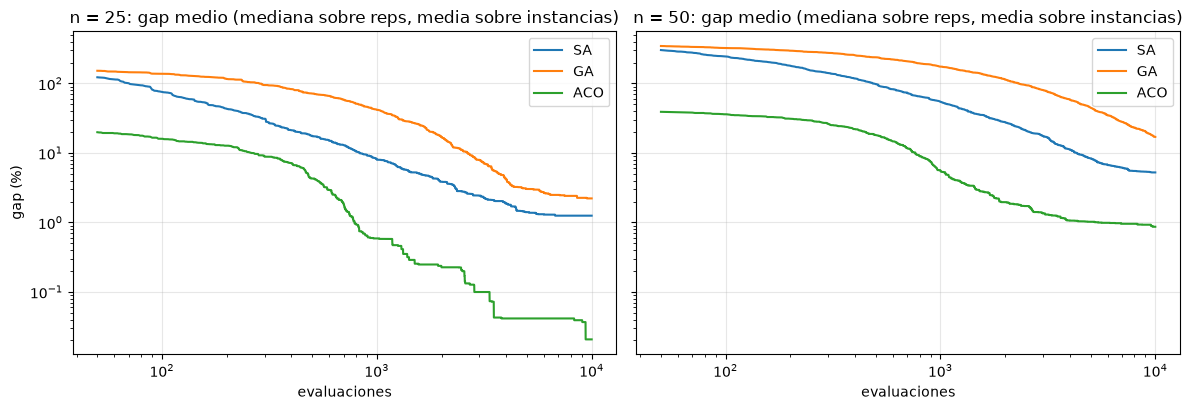

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
xs = np.arange(1, PRESUPUESTO + 1)
for ax, n in zip(axs, [25, 50]):
    for nom, col in zip(["SA", "GA", "ACO"], ["C0", "C1", "C2"]):
        curvas = []
        for b in BANCO:
            if b["n"] != n: continue
            g = 100 * (TRAZAS[(b["id"], nom)] - bks[b["id"]]) / bks[b["id"]]    # reps x B
            curvas.append(np.median(g, axis=0))
        c = np.mean(curvas, axis=0)
        ax.plot(xs[49:], c[49:], color=col, label=nom)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"n = {n}: gap medio (mediana sobre reps, media sobre instancias)")
    ax.set_xlabel("evaluaciones"); ax.legend()
axs[0].set_ylabel("gap (%)"); plt.tight_layout(); plt.show()

## 6. Consistencia: varianza, boxplots y tasa de éxito

Dos algoritmos con la misma media pueden ser muy distintos: uno estable, otro que alterna entre excelente y desastroso.
Medimos la **consistencia** con:

- **Desviación estándar** y **coeficiente de variación** del gap (¡ojo!: el gap puede ser ~0, y el CV explota; aquí
  preferimos el **rango intercuartílico**, IQR, robusto).
- **Boxplots** por algoritmo y por clase de instancia: muestran mediana, cuartiles y *outliers*.
- **Tasa de éxito** a un umbral $\varepsilon$: $\mathrm{SR}_\varepsilon=\Pr(\mathrm{gap}\le\varepsilon)$ estimada como fracción
  de corridas. Es un estimador binomial, así que le asociamos un intervalo de confianza de Wilson.

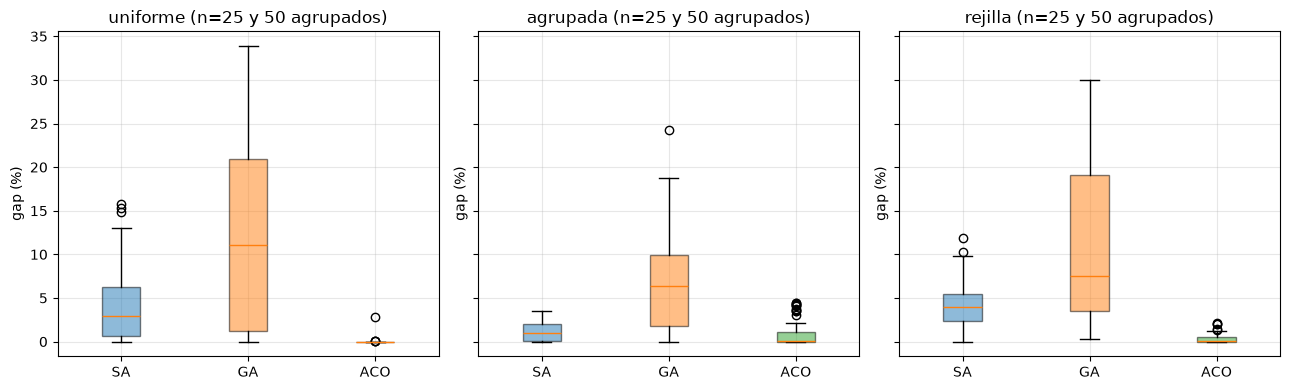

       std     IQR
alg               
ACO  1.106   0.210
GA   9.095  16.071
SA   3.599   4.675


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, tipo in zip(axs, ["uniforme", "agrupada", "rejilla"]):
    datos = [df[(df.tipo == tipo) & (df.alg == a)].gap.values for a in ["SA", "GA", "ACO"]]
    bp = ax.boxplot(datos, tick_labels=["SA", "GA", "ACO"], showfliers=True, patch_artist=True)
    for p, c in zip(bp["boxes"], ["C0", "C1", "C2"]): p.set_alpha(0.5); p.set_facecolor(c)
    ax.set_title(f"{tipo} (n=25 y 50 agrupados)"); ax.set_ylabel("gap (%)")
plt.tight_layout(); plt.show()

disp = df.groupby("alg").gap.agg(std="std", IQR=lambda x: x.quantile(.75) - x.quantile(.25)).round(3)
print(disp.to_string())

In [12]:
def wilson(k, n, z=1.96):
    # intervalo de Wilson para una proporción
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

filas = []
for eps in [1, 2, 5]:
    for a in ["SA", "GA", "ACO"]:
        g = df[df.alg == a].gap.values; k = int((g <= eps).sum()); lo, hi = wilson(k, len(g))
        filas.append(dict(umbral_pct=eps, alg=a, tasa_exito=round(k / len(g), 3), IC95=f"[{lo:.3f}, {hi:.3f}]"))
print(pd.DataFrame(filas).to_string(index=False))
print("\n(Pooled sobre 12 instancias x 12 reps = 144 corridas por algoritmo. Las corridas dentro de una instancia no son"
      " independientes entre sí en cuanto a dificultad; el IC es aproximado.)")

 umbral_pct alg  tasa_exito           IC95
          1  SA       0.326 [0.255, 0.407]
          1  GA       0.146 [0.097, 0.213]
          1 ACO       0.847 [0.780, 0.897]
          2  SA       0.444 [0.366, 0.526]
          2  GA       0.222 [0.162, 0.297]
          2 ACO       0.896 [0.835, 0.936]
          5  SA       0.736 [0.659, 0.801]
          5  GA       0.431 [0.353, 0.512]
          5 ACO       1.000 [0.974, 1.000]

(Pooled sobre 12 instancias x 12 reps = 144 corridas por algoritmo. Las corridas dentro de una instancia no son independientes entre sí en cuanto a dificultad; el IC es aproximado.)


## 7. Tiempo de ejecución y tasa de crecimiento con el tamaño

Interesa saber cuánto **crece el costo** al aumentar $n$. Modelo empírico de ley de potencias:
$$t(n)\approx a\,n^{b}\quad\Longleftrightarrow\quad \log t=\log a+b\log n,$$
y estimamos $b$ por regresión lineal en escala log-log (con intervalo de confianza del 95 % para la pendiente).
Es **la tasa de crecimiento empírica** a presupuesto fijo, no la complejidad asintótica en el peor caso. Para que sea
informativo, medimos:

- $t(n)$: tiempo de pared de una corrida con presupuesto de 3000 evaluaciones.
- **Soluciones exploradas por segundo** $= \text{evaluaciones}/t$. Es el "throughput" del algoritmo y es lo que
  hace injusta la comparación por evaluaciones entre SA ($O(1)$ por evaluación) y GA/ACO ($O(n)$).

Medimos con repeticiones y usamos el **mínimo** o la mediana del tiempo (el mínimo es robusto al ruido del sistema
operativo, que solo puede *añadir* tiempo).

Tiempo mediano por corrida (s), presupuesto = 3000 evaluaciones:
alg      SA      GA     ACO
n                          
20   0.0054  0.1979  0.1162
30   0.0199  0.1901  0.2501
50   0.0062  0.2672  0.3429
75   0.0051  0.2319  0.8397
100  0.0061  0.4438  0.6319
150  0.0055  0.1107  2.0038
200  0.0217  0.2663  3.7787


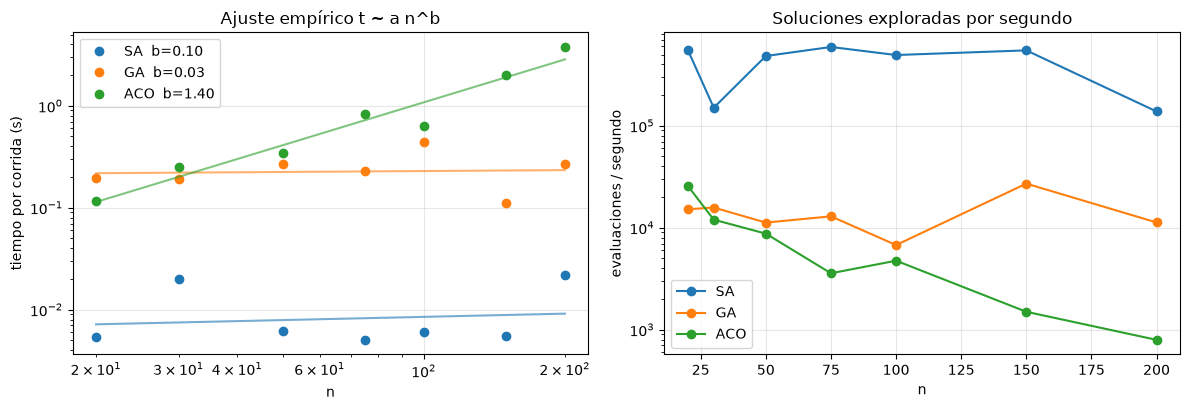

alg  exponente_b          IC95     R2
 SA        0.105 [-0.77, 0.98] 0.0186
 GA        0.030 [-0.55, 0.61] 0.0036
ACO        1.399  [1.01, 1.78] 0.9457


In [13]:
NS = [20, 30, 50, 75, 100, 150, 200]
B_T = 3000; filas = []
for n in NS:
    pts, D = generar_instancia(n, "uniforme", np.random.default_rng([14, 7, n]))
    for ai, (nom, f) in enumerate(ALG.items()):
        for r in range(3):
            t0 = time.perf_counter(); f(D, B_T, np.random.default_rng(r), traza=False); seg = time.perf_counter() - t0
            filas.append(dict(n=n, alg=nom, rep=r, seg=seg))
dt = pd.DataFrame(filas)
tt = dt.groupby(["n", "alg"]).seg.median().unstack()[["SA", "GA", "ACO"]]
print("Tiempo mediano por corrida (s), presupuesto =", B_T, "evaluaciones:")
print(tt.round(4).to_string())

# ajuste log-log con statsmodels
res = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for nom, col in zip(["SA", "GA", "ACO"], ["C0", "C1", "C2"]):
    x = np.log(np.array(NS)); y = np.log(tt[nom].values)
    ols = sm.OLS(y, sm.add_constant(x)).fit(); b = ols.params[1]; lo, hi = ols.conf_int()[1]
    res.append(dict(alg=nom, exponente_b=round(b, 3), IC95=f"[{lo:.2f}, {hi:.2f}]", R2=round(ols.rsquared, 4)))
    axs[0].loglog(NS, tt[nom].values, "o", color=col, label=f"{nom}  b={b:.2f}")
    axs[0].loglog(NS, np.exp(ols.params[0]) * np.array(NS)**b, "-", color=col, alpha=.6)
    axs[1].plot(NS, B_T / tt[nom].values, "o-", color=col, label=nom)
axs[0].set_xlabel("n"); axs[0].set_ylabel("tiempo por corrida (s)"); axs[0].set_title("Ajuste empírico t ~ a n^b"); axs[0].legend()
axs[1].set_xlabel("n"); axs[1].set_ylabel("evaluaciones / segundo"); axs[1].set_yscale("log"); axs[1].set_title("Soluciones exploradas por segundo"); axs[1].legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame(res).to_string(index=False))

In [14]:
# Throughput a n = 50 (la mediana de las corridas del experimento principal ya incluye el tiempo)
thr = df[df.n == 50].groupby("alg").apply(lambda g: (g.evals / g.seg).median()).round(0)
print("Evaluaciones por segundo (mediana, n = 50, B = 10000):"); print(thr.to_string())
print("\nRazón SA / ACO  :", round(thr["SA"] / thr["ACO"], 1), "x")
print("Razón SA / GA   :", round(thr["SA"] / thr["GA"], 1), "x")

Evaluaciones por segundo (mediana, n = 50, B = 10000):
alg
ACO     21031.0
GA      34379.0
SA     774977.0

Razón SA / ACO  : 36.8 x
Razón SA / GA   : 22.5 x


**Lectura.** El exponente $b$ resume cómo escala el tiempo a presupuesto fijo; no dice nada sobre cómo escala la
*calidad*. **Mira el intervalo de confianza antes de interpretar $b$**: si incluye 0 (y el $R^2$ es bajo), el tiempo no crece
de forma detectable en este rango de $n$ porque dominan los costos fijos por evaluación del intérprete (bucle de Python,
generación de números aleatorios, selección por torneo), no el tamaño del problema. Esto ocurre cuando cada evaluación es
$O(1)$ (SA con delta) o cuando el trabajo por individuo está vectorizado y es pequeño. Para ACO el trabajo por tour sí crece con $n$
(se construye con $n$ pasos y una matriz de probabilidades de tamaño $m\times n$), y el ajuste lo refleja. El exponente medido en un
rango estrecho de $n$ y con constantes de Python **no es** la complejidad teórica.

Un informe completo debe medir también cómo crece el **presupuesto necesario para alcanzar cierto gap** con $n$ (o la
calidad con presupuesto proporcional a $n$). Lo hacemos de forma parcial en las secciones 9-10.

## 8. Presupuesto en evaluaciones vs. presupuesto en tiempo

Hasta ahora todos los métodos tuvieron **10 000 evaluaciones**. Pero con $n=50$, SA hace esas evaluaciones en una fracción
del tiempo que gasta ACO. Si el usuario real tiene un **límite de tiempo**, el ranking puede cambiar. Repetimos el estudio
en 6 instancias (la primera de cada combinación tipo × tamaño) con un **reloj de 0.3 s por corrida** y comparamos con el
ranking a evaluaciones iguales sobre esas mismas instancias.

Nota técnica: en modo tiempo, SA ajusta su temperatura según el **tiempo transcurrido** (no según el contador de evaluaciones), de modo
que todos los algoritmos usan su presupuesto completo para enfriar/converger. Las corridas de este bloque **no son
reproducibles bit a bit** (dependen del reloj), solo estadísticamente.

In [15]:
TMAX, REPS_T = 0.3, 6
sub = [b for b in BANCO if b["k"] == 0]
filas = []
for b in sub:
    for ai, (nom, f) in enumerate(ALG.items()):
        for r in range(REPS_T):
            L, tour, _, ev = f(b["D"], 2_000_000, rng_corrida(b["id"], ai + 10, r), tmax=TMAX, traza=False)
            assert es_permutacion(tour, b["n"])
            filas.append(dict(inst=b["id"], alg=nom, rep=r, L=L, evals=ev))
dft = pd.DataFrame(filas)
dft["bks"] = dft.inst.map(lambda i: min(bks[i], dft[dft.inst == i].L.min())); dft["gap"] = 100 * (dft.L - dft.bks) / dft.bks
Mt = dft.pivot_table(index="inst", columns="alg", values="gap", aggfunc="median")[["SA", "GA", "ACO"]]
Me = M.loc[Mt.index]
comp = pd.DataFrame({"gap mediano (evals iguales)": Me.median(), "rango medio (evals iguales)": Me.rank(axis=1).mean(),
                     "gap mediano (tiempo igual)": Mt.median(), "rango medio (tiempo igual)": Mt.rank(axis=1).mean(),
                     "evals usadas en 0.3 s (mediana)": dft.groupby("alg").evals.median()}).round(3)
print(f"6 instancias, {REPS_T} reps, reloj = {TMAX} s por corrida")
print(comp.to_string())
print("\nOrden por rango medio, evaluaciones iguales:", list(comp["rango medio (evals iguales)"].sort_values().index))
print("Orden por rango medio, tiempo igual        :", list(comp["rango medio (tiempo igual)"].sort_values(kind="stable").index))

6 instancias, 6 reps, reloj = 0.3 s por corrida
     gap mediano (evals iguales)  rango medio (evals iguales)  gap mediano (tiempo igual)  rango medio (tiempo igual)  evals usadas en 0.3 s (mediana)
alg                                                                                                                                                   
ACO                        0.014                          1.0                       0.079                         1.5                           9600.0
GA                         6.802                          3.0                      10.802                         3.0                           8230.0
SA                         1.970                          2.0                       0.011                         1.5                         205056.0

Orden por rango medio, evaluaciones iguales: ['ACO', 'SA', 'GA']
Orden por rango medio, tiempo igual        : ['ACO', 'SA', 'GA']


**Moraleja.** La métrica de presupuesto **es parte del experimento**: define la pregunta que se contesta. Con evaluaciones
iguales se compara la *eficiencia muestral* (cuánta información extrae el método de cada evaluación); con tiempo igual, la
*eficiencia computacional* (útil para el usuario final, pero dependiente de implementación y máquina). Compara las dos
mitades de la tabla (en particular lo que le pasa al gap de SA, que con el mismo reloj ejecuta muchísimas más evaluaciones que
ACO y GA): es una **prueba de sensibilidad** que debería acompañar cualquier comparación. Ten en cuenta que aquí hay solo
6 instancias y 6 repeticiones, por lo que las diferencias pequeñas entre rangos no son concluyentes.

## 9. Perfiles de desempeño de Dolan–Moré

Los **perfiles de desempeño** (Dolan y Moré, 2002) resumen en una sola figura la comparación de $|S|$ solvers sobre $|P|$
problemas sin depender de la escala de cada problema ni de la elección de un solo número.

Sea $c_{p,s}$ el costo del solver $s$ en el problema $p$ (aquí: **largo medio del tour** sobre las repeticiones; también se
usa tiempo hasta un objetivo). La **razón de desempeño** es
$$r_{p,s}=\frac{c_{p,s}}{\min_{s'}c_{p,s'}}\ \ge 1,$$
y el **perfil** del solver $s$ es la función de distribución acumulada de esas razones:
$$\rho_s(\tau)=\frac{1}{|P|}\,\bigl|\{p\in P:\ r_{p,s}\le \tau\}\bigr|.$$

- $\rho_s(1)$: fracción de problemas en que $s$ es el mejor (eficiencia).
- $\rho_s(\tau)$ para $\tau$ grande: fracción de problemas que $s$ resuelve "razonablemente" (robustez).
- Un perfil que está por encima de los demás para todo $\tau$ **domina**.

Con instancias de fallos (no alcanzar el objetivo) se fija $r_{p,s}=\infty$. Calculamos dos perfiles: sobre la **calidad
final** y sobre las **evaluaciones hasta alcanzar un objetivo** común (ver la definición del objetivo en la sección 10).

Evaluaciones medianas hasta gap <= 3.0 % (inf = no se alcanza en >=50% de reps); instancias con inf por alg:
{'SA': 5, 'GA': 8, 'ACO': 1}


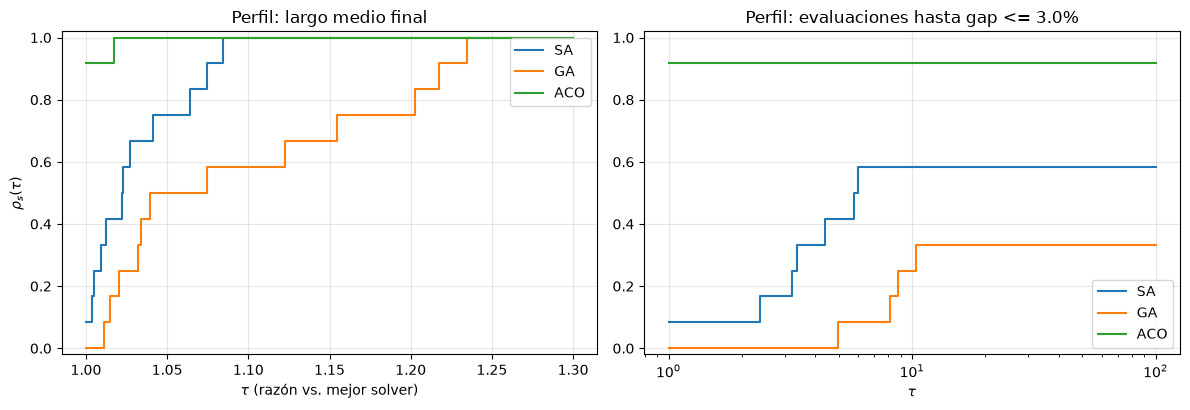

rho_s(1) calidad final: {'SA': 0.083, 'GA': 0.0, 'ACO': 0.917}


In [16]:
def perfil(C, taus):
    # C: DataFrame problemas x solvers con costos > 0 (inf permitido). Devuelve rho_s(tau)
    R = C.div(C.min(axis=1), axis=0)
    return {s: np.array([(R[s] <= t).mean() for t in taus]) for s in C.columns}

# (a) calidad final: largo medio de las reps
Cq = df.pivot_table(index="inst", columns="alg", values="L", aggfunc="mean")[["SA", "GA", "ACO"]]
taus = np.linspace(1, 1.30, 300)
P_q = perfil(Cq, taus)

# (b) evaluaciones para alcanzar un objetivo: gap <= 3 % respecto al BKS (mediana sobre reps; inf si <50 % de reps lo logra)
def evals_a_objetivo(tr, objetivo):
    # tr: reps x B. Devuelve vector (inf si nunca)
    hit = tr <= objetivo
    return np.where(hit.any(axis=1), hit.argmax(axis=1) + 1.0, np.inf)

OBJ_PCT = 3.0
Ct = pd.DataFrame({nom: [np.median(evals_a_objetivo(TRAZAS[(b["id"], nom)], bks[b["id"]] * (1 + OBJ_PCT / 100))) for b in BANCO]
                   for nom in ["SA", "GA", "ACO"]}, index=[b["id"] for b in BANCO])
print("Evaluaciones medianas hasta gap <=", OBJ_PCT, "% (inf = no se alcanza en >=50% de reps); instancias con inf por alg:")
print(np.isinf(Ct).sum().to_dict())
taus_t = np.logspace(0, 2, 300)
Cts = Ct.copy().replace(np.inf, np.nan)
mn = Cts.min(axis=1)
P_t = {}
for s in Ct.columns:
    r = (Ct[s] / mn).replace(np.nan, np.inf)           # inf/min = inf (no resuelto)
    r[np.isinf(Ct[s])] = np.inf
    P_t[s] = np.array([(r <= t).mean() for t in taus_t])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for s, c in zip(["SA", "GA", "ACO"], ["C0", "C1", "C2"]):
    axs[0].step(taus, P_q[s], where="post", color=c, label=s); axs[1].step(taus_t, P_t[s], where="post", color=c, label=s)
axs[0].set_xlabel(r"$\tau$ (razón vs. mejor solver)"); axs[0].set_ylabel(r"$\rho_s(\tau)$"); axs[0].set_title("Perfil: largo medio final")
axs[1].set_xscale("log"); axs[1].set_xlabel(r"$\tau$"); axs[1].set_title(f"Perfil: evaluaciones hasta gap <= {OBJ_PCT}%")
for ax in axs: ax.legend(); ax.set_ylim(-0.02, 1.02)
plt.tight_layout(); plt.show()
print("rho_s(1) calidad final:", {s: round(float(P_q[s][0]), 3) for s in P_q})

**Precauciones.** (i) El perfil depende del **conjunto de solvers**: agregar o quitar uno puede cambiar el orden
relativo de los demás (Gould y Scott, 2016). (ii) Con $|P|=12$, $\rho_s$ solo toma valores múltiplos de $1/12$; el
perfil es un resumen descriptivo, no una prueba estadística. (iii) La razón usa el **mínimo entre solvers**, que
puede ser un solver mediocre en ese problema: complementar con el BKS y el gap.

## 10. Curvas de tiempo-hasta-el-objetivo (ECDF / *run-length distributions*)

Para algoritmos estocásticos con **criterio de éxito** (alcanzar un gap $\le\varepsilon$), el *tiempo* (o las evaluaciones)
$T_\varepsilon$ hasta lograrlo es una variable aleatoria. Su distribución acumulada
$$F_\varepsilon(t)=\Pr(T_\varepsilon\le t)$$
se llama **distribución de longitud de corrida** (*run-length distribution*, RLD; Hoos y Stützle, 2005) o, si $t$ es tiempo,
*time-to-target* (TTT). La estimamos con la **ECDF** sobre las corridas, tratando las que *no* alcanzan el objetivo como
**censuradas** ($T=\infty$): la ECDF se estabiliza en la tasa de éxito, no en 1.

La RLD permite ver lo que un número no muestra: si el algoritmo es **rápido pero poco fiable** (sube pronto y se aplana por
debajo de 1), o **lento pero seguro**, y si conviene **reiniciar**: una RLD con meseta temprana sugiere que reiniciar
aumenta la probabilidad de éxito por unidad de cómputo. Aquí agrupamos las corridas de todas las instancias (cada una
medida contra su propio BKS).

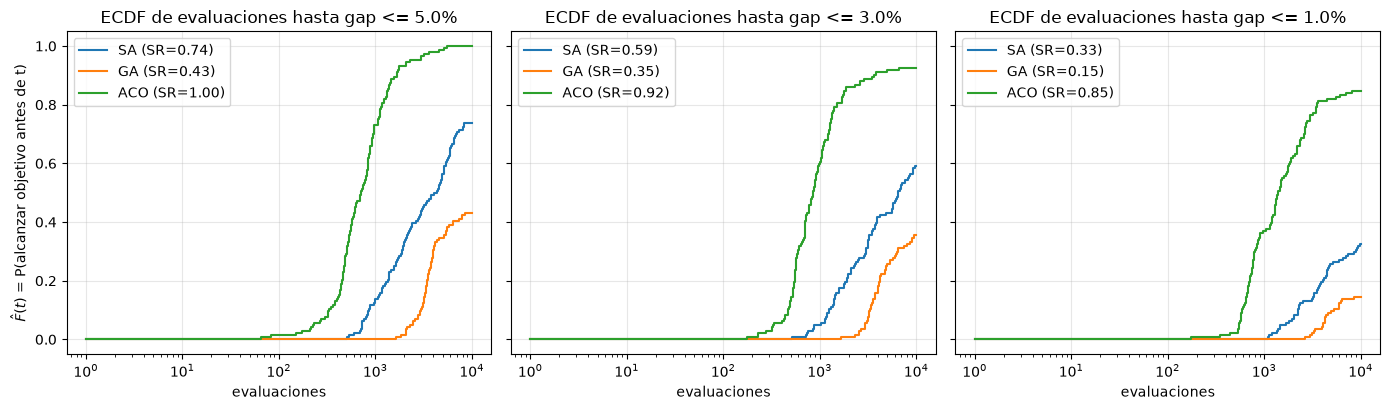

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, eps in zip(axs, [5.0, 3.0, 1.0]):
    for nom, c in zip(["SA", "GA", "ACO"], ["C0", "C1", "C2"]):
        T = np.concatenate([evals_a_objetivo(TRAZAS[(b["id"], nom)], bks[b["id"]] * (1 + eps / 100)) for b in BANCO])
        fin = np.sort(T[np.isfinite(T)])
        xs_ = np.concatenate([[1], fin, [PRESUPUESTO]]); ys_ = np.concatenate([[0], np.arange(1, len(fin) + 1) / len(T), [len(fin) / len(T)]])
        ax.step(xs_, ys_, where="post", color=c, label=f"{nom} (SR={len(fin)/len(T):.2f})")
    ax.set_xscale("log"); ax.set_title(f"ECDF de evaluaciones hasta gap <= {eps}%"); ax.set_xlabel("evaluaciones"); ax.legend(loc="upper left")
axs[0].set_ylabel(r"$\hat F(t)$ = P(alcanzar objetivo antes de t)"); plt.tight_layout(); plt.show()

In [18]:
# Mediana condicional y probabilidad de éxito a distintos presupuestos
filas = []
for eps in [5.0, 3.0, 1.0]:
    for nom in ["SA", "GA", "ACO"]:
        T = np.concatenate([evals_a_objetivo(TRAZAS[(b["id"], nom)], bks[b["id"]] * (1 + eps / 100)) for b in BANCO])
        fin = T[np.isfinite(T)]
        filas.append(dict(objetivo_pct=eps, alg=nom, P_exito_10k=round(len(fin) / len(T), 3),
                          P_exito_2k=round(float((T <= 2000).mean()), 3),
                          mediana_evals_condicional=(int(np.median(fin)) if len(fin) else None)))
print(pd.DataFrame(filas).to_string(index=False))
print("\nObjetivo 'gap<=eps' siempre respecto al BKS; el BKS se define a partir de estas mismas corridas, así que"
      " la tasa de éxito en eps=0 no sería 0 pero sí sesgada a favor de los algoritmos que aportaron el BKS.")

 objetivo_pct alg  P_exito_10k  P_exito_2k  mediana_evals_condicional
          5.0  SA        0.736       0.333                       2239
          5.0  GA        0.431       0.014                       3530
          5.0 ACO        1.000       0.931                        710
          3.0  SA        0.590       0.222                       2991
          3.0  GA        0.354       0.007                       4031
          3.0 ACO        0.924       0.861                        802
          1.0  SA        0.326       0.069                       3549
          1.0  GA        0.146       0.000                       4295
          1.0 ACO        0.847       0.625                       1263

Objetivo 'gap<=eps' siempre respecto al BKS; el BKS se define a partir de estas mismas corridas, así que la tasa de éxito en eps=0 no sería 0 pero sí sesgada a favor de los algoritmos que aportaron el BKS.


## 11. Pruebas estadísticas

La estadística descriptiva dice *qué pasó*; las pruebas dicen si la diferencia es **creíble frente al ruido muestral**. En
comparaciones de algoritmos sobre un conjunto de instancias se recomienda un enfoque **no paramétrico** (Demšar, 2006;
García y Herrera, 2008), porque los gaps no son normales, tienen escalas distintas y las muestras (instancias) son pocas.

### 11.1 Dos algoritmos: Wilcoxon de rangos con signo (pareado)

Datos: $d_p=m_{p,A}-m_{p,B}$ por instancia $p$, con $m$ una medida resumen (mediana de las repeticiones). Se ordenan $|d_p|$,
se suman los rangos de los positivos $W^+$ y de los negativos $W^-$. Hipótesis nula: la mediana de $d_p$ es 0. Supuestos:
las instancias son una muestra independiente y la distribución de $d$ es simétrica.
El tamaño de efecto asociado es la **correlación biserial por rangos** $r_{rb}=(W^+-W^-)/(W^++W^-)\in[-1,1]$
(con $d=m_A-m_B$ y menor-es-mejor, $r_{rb}<0$ favorece a $A$).

### 11.2 Varios algoritmos: Friedman y post hoc

Para $k$ algoritmos sobre $N$ instancias (bloques): se rankea dentro de cada instancia y se compara el rango medio
$\bar R_j$ de cada algoritmo con
$$\chi_F^2=\frac{12N}{k(k+1)}\Bigl[\sum_j \bar R_j^2-\frac{k(k+1)^2}{4}\Bigr]\ \sim\ \chi^2_{k-1}\ \text{(aprox.)}.$$
Si se rechaza $H_0$, las comparaciones por pares usan la **diferencia crítica de Nemenyi**
$$CD=\frac{q_{\alpha,k}}{\sqrt2}\sqrt{\frac{k(k+1)}{6N}},$$
con $q_{\alpha,k}$ el cuantil de la distribución del rango estudentizado, o bien **Wilcoxon con corrección de Holm**
(más potente que Nemenyi cuando se comparan pocos pares, Demšar, 2006).

### 11.3 Tamaño de efecto sobre las corridas: $A_{12}$ de Vargha–Delaney

Con $R$ corridas por algoritmo en una instancia, $A_{12}=\Pr(X_A<X_B)+\tfrac12\Pr(X_A=X_B)$ (aquí $X$ = gap; menor es
mejor, así que $A_{12}>0.5$ favorece a $A$). $A_{12}=0.5$ significa "sin efecto"; los umbrales tradicionales de efecto
pequeño, mediano y grande son $A_{12}\approx0.56,\,0.64,\,0.71$ (o sus simétricos $0.44,\,0.36,\,0.29$). Es el estadístico $U$ de
Mann–Whitney normalizado por $R_AR_B$. Lo calculamos por instancia y promediamos.

Friedman: chi2 = 20.167  (manual: 20.167), gl = 2, p = 4.177e-05   [N = 12 instancias, k = 3 algoritmos]
Rangos medios: {'SA': 2.0, 'GA': 2.917, 'ACO': 1.083}
Nemenyi: q_0.05,3 = 3.314  ->  CD = 0.957 (diferencia de rangos medios necesaria)
   SA vs GA   |dif rangos| = 0.917  ->  no significativa
   SA vs ACO  |dif rangos| = 0.917  ->  no significativa
   GA vs ACO  |dif rangos| = 1.833  ->  significativa


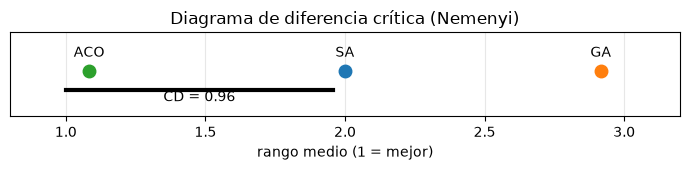

In [19]:
alg = ["SA", "GA", "ACO"]; N, k = M.shape
# --- Friedman
chi2, p_f = stats.friedmanchisquare(*[M[a].values for a in alg])
Rm = RANGOS.mean()
# comprobación manual del estadístico
chi2_man = 12 * N / (k * (k + 1)) * ((Rm**2).sum() - k * (k + 1)**2 / 4)
print(f"Friedman: chi2 = {chi2:.3f}  (manual: {chi2_man:.3f}), gl = {k-1}, p = {p_f:.4g}   [N = {N} instancias, k = {k} algoritmos]")
print("Rangos medios:", Rm.round(3).to_dict())
# scipy.friedmanchisquare no corrige empates en la forma manual; coincide si no hay empates (aquí se comprueba).

# --- Nemenyi
q = stats.studentized_range.ppf(0.95, k, np.inf)
CD = q / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * N))
print(f"Nemenyi: q_0.05,{k} = {q:.3f}  ->  CD = {CD:.3f} (diferencia de rangos medios necesaria)")
for i in range(k):
    for j in range(i + 1, k):
        dif = abs(Rm[alg[i]] - Rm[alg[j]])
        print(f"  {alg[i]:>3s} vs {alg[j]:<3s}  |dif rangos| = {dif:.3f}  ->  {'significativa' if dif > CD else 'no significativa'}")

# diagrama de diferencia crítica simplificado
fig, ax = plt.subplots(figsize=(7, 1.8))
for a in alg: ax.plot(Rm[a], 0, "o", ms=9); ax.annotate(a, (Rm[a], 0), xytext=(0, 10), textcoords="offset points", ha="center")
ax.plot([1, 1 + CD], [-0.5, -0.5], "k-", lw=3); ax.text(1 + CD / 2, -0.8, f"CD = {CD:.2f}", ha="center")
ax.set_xlim(0.8, k + 0.2); ax.set_ylim(-1.2, 1); ax.set_yticks([]); ax.set_xlabel("rango medio (1 = mejor)")
ax.set_title("Diagrama de diferencia crítica (Nemenyi)"); plt.tight_layout(); plt.show()

In [20]:
# --- Wilcoxon pareado + Holm + tamaño de efecto
def rank_biserial(d):
    d = d[d != 0]; r = stats.rankdata(np.abs(d)); Wp, Wm = r[d > 0].sum(), r[d < 0].sum()
    return (Wp - Wm) / (Wp + Wm)

def a12(x, y):
    # P(X<Y) + 0.5 P(X=Y): "x mejor que y" cuando menor es mejor
    x = np.asarray(x)[:, None]; y = np.asarray(y)[None, :]
    return float((x < y).mean() + 0.5 * (x == y).mean())

pares = [("SA", "GA"), ("SA", "ACO"), ("GA", "ACO")]
filas = []
for a, b in pares:
    d = M[a].values - M[b].values
    W = stats.wilcoxon(M[a].values, M[b].values, method="auto")
    a12s = np.mean([a12(df[(df.inst == i) & (df.alg == a)].gap, df[(df.inst == i) & (df.alg == b)].gap) for i in M.index])
    filas.append(dict(par=f"{a} vs {b}", W=W.statistic, p_bruto=W.pvalue, r_biserial=rank_biserial(d), A12_medio=a12s,
                      inst_A_mejor=int((d < 0).sum()), inst_B_mejor=int((d > 0).sum())))
tw = pd.DataFrame(filas)
tw["p_Holm"] = multipletests(tw.p_bruto, method="holm")[1]
print(tw.round(4).to_string(index=False))
print("\nA12 > 0.5 significa que el PRIMER algoritmo da gaps menores (mejores) con mayor probabilidad.")

      par   W  p_bruto  r_biserial  A12_medio  inst_A_mejor  inst_B_mejor  p_Holm
 SA vs GA 4.0   0.0034     -0.8974     0.8356            11             1  0.0068
SA vs ACO 5.0   0.0049      0.8718     0.1635             1            11  0.0068
GA vs ACO 0.0   0.0005      1.0000     0.0362             0            12  0.0015

A12 > 0.5 significa que el PRIMER algoritmo da gaps menores (mejores) con mayor probabilidad.


**Cómo leer la tabla.** Distingue tres cosas: (1) $p$ Holm: ¿hay evidencia de que los dos algoritmos difieren, tras corregir por
las 3 comparaciones? (2) $r_{rb}$ y $A_{12}$: ¿cuán grande es la diferencia? (3) Instancias ganadas: ¿es consistente?
Nota que Nemenyi (que compara *todos* los pares con un solo umbral) es más conservador que Wilcoxon + Holm: puede dejar sin
declarar diferencias que Wilcoxon sí detecta, como ocurre con alguno de los pares de arriba. Con **pocas instancias** ($N=12$), la potencia de Wilcoxon es limitada: no rechazar $H_0$ **no** prueba equivalencia. Y con
muchas repeticiones es fácil obtener $p$ minúsculos para efectos irrelevantes: por eso el tamaño de efecto es obligatorio.

### 11.4 Qué no hacer: tratar las corridas como muestras independientes de instancias

Para ilustrar la pseudo-replicación, comparamos SA vs ACO con Wilcoxon **sobre las 144 corridas apareadas por (instancia, repetición)**
(esto trata las réplicas como si fueran instancias) y comparamos el $p$ con el del análisis correcto a nivel de instancia
(arriba). El resultado casi siempre sale "más significativo" y por tanto **engañoso** para la pregunta de generalización
a *instancias nuevas*.

In [21]:
ya = df[df.alg == "SA"].sort_values(["inst", "rep"]).gap.values
yb = df[df.alg == "ACO"].sort_values(["inst", "rep"]).gap.values
p_corridas = stats.wilcoxon(ya, yb).pvalue
p_inst = tw.loc[tw.par == "SA vs ACO", "p_bruto"].iloc[0]
print(f"Wilcoxon SA vs ACO  |  a nivel de corrida (n = {len(ya)}, incorrecto para generalizar): p = {p_corridas:.3g}")
print(f"                    |  a nivel de instancia (n = {N}, correcto):                           p = {p_inst:.3g}")

Wilcoxon SA vs ACO  |  a nivel de corrida (n = 144, incorrecto para generalizar): p = 8.34e-18
                    |  a nivel de instancia (n = 12, correcto):                           p = 0.00488


## 12. ¿Cuántas repeticiones necesito?

El error estándar de la media del gap en una instancia es $\sigma/\sqrt R$, así que **duplicar la precisión cuesta
cuadruplicar las corridas**. Lo verificamos empíricamente en una instancia: corremos 60 repeticiones de SA, y para cada
$R\in\{3,5,10,20,40\}$ extraemos muchos subconjuntos aleatorios de $R$ corridas y medimos la dispersión de la media muestral.
La curva debe seguir $\sigma/\sqrt R$.

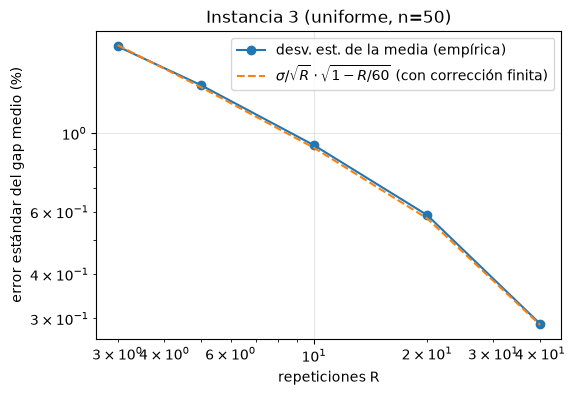

sigma del gap en esta instancia = 3.149 %  ->  para un IC95% de semiancho 0.5 % se necesitan R ~ 153 corridas


In [22]:
b = BANCO[3]
g60 = np.array([100 * (sa_tsp(b["D"], PRESUPUESTO, np.random.default_rng(np.random.SeedSequence(ENTROPIA, spawn_key=(77, r))))[0] - bks[b["id"]]) / bks[b["id"]]
                for r in range(60)])
sigma = g60.std(ddof=1); rs = [3, 5, 10, 20, 40]; rg = np.random.default_rng(0)
sd_medias = [np.std([rg.choice(g60, R, replace=False).mean() for _ in range(2000)]) for R in rs]
plt.figure(figsize=(6, 4))
plt.loglog(rs, sd_medias, "o-", label="desv. est. de la media (empírica)")
plt.loglog(rs, sigma / np.sqrt(rs) * np.sqrt(1 - np.array(rs) / 60), "--", label=r"$\sigma/\sqrt{R}\cdot\sqrt{1-R/60}$ (con corrección finita)")
plt.xlabel("repeticiones R"); plt.ylabel("error estándar del gap medio (%)"); plt.legend(); plt.title(f"Instancia {b['id']} ({b['tipo']}, n={b['n']})"); plt.show()
print(f"sigma del gap en esta instancia = {sigma:.3f} %  ->  para un IC95% de semiancho 0.5 % se necesitan R ~ {int(np.ceil((1.96*sigma/0.5)**2))} corridas")

## 13. Lista de verificación para un estudio computacional

- [ ] Instancias variadas en **tipo y tamaño**, generadas con semilla; instancias de ajuste y de prueba **separadas** (notebook 15).
- [ ] Mismo **presupuesto** (y se reporta cuál) y misma política de ajuste de parámetros para todos los métodos.
- [ ] $R$ corridas independientes con semillas registradas; el $R$ se elige para una precisión objetivo.
- [ ] Referencia explícita (óptimo, cota, o BKS) y su origen; el gap es contra esa referencia.
- [ ] Tendencia **y** dispersión; boxplots; tasa de éxito con intervalo.
- [ ] Costo: tiempo, evaluaciones y *throughput*; escalamiento con $n$.
- [ ] Perfiles/ECDF para visión global y *anytime*.
- [ ] Pruebas no paramétricas a nivel de **instancia**, corrección por comparaciones múltiples y **tamaño de efecto**.
- [ ] Código y semillas publicados.

## Ventajas y limitaciones de las herramientas vistas

| Herramienta | Ventaja | Limitación |
|---|---|---|
| Gap vs BKS | Interpretable, adimensional | Depende de la calidad del BKS; sesgado si el BKS sale de los mismos algoritmos |
| Ranking / Friedman | Robusto a escala, estándar | Ignora la magnitud; pocas instancias = poca potencia |
| Boxplot / IQR | Muestra distribución completa | No resume en un solo número |
| Perfil Dolan–Moré | Resumen global sin escala | Depende del conjunto de solvers; descriptivo |
| ECDF / RLD | Muestra velocidad, fiabilidad y utilidad de reinicios | Requiere un objetivo fijado de antemano |
| Wilcoxon + Holm | Pocos supuestos | Solo compara pares; efecto no se ve en $p$ |
| $A_{12}$, $r_{rb}$ | Tamaño de efecto interpretable | Umbrales convencionales, no universales |
| Ajuste log-log | Resume escalamiento empírico | Constantes del lenguaje; rango de $n$ limitado |

In [23]:
# Resumen numérico final calculado desde los resultados (no escrito a mano)
print("RESUMEN CALCULADO")
print("- Mediana del gap (%):", df.groupby("alg").gap.median().round(3).to_dict())
print("- Rango medio Friedman:", Rm.round(2).to_dict(), f"(p = {p_f:.3g})")
print("- Throughput SA/ACO a n=50:", round(thr["SA"] / thr["ACO"], 1), "x")
print("- p Holm por pares:", dict(zip(tw.par, tw.p_Holm.round(4))))

RESUMEN CALCULADO
- Mediana del gap (%): {'ACO': 0.0, 'GA': 7.169, 'SA': 2.314}
- Rango medio Friedman: {'SA': 2.0, 'GA': 2.92, 'ACO': 1.08} (p = 4.18e-05)
- Throughput SA/ACO a n=50: 36.8 x
- p Holm por pares: {'SA vs GA': 0.0068, 'SA vs ACO': 0.0068, 'GA vs ACO': 0.0015}


## Resumen

- Evaluar una metaheurística es **inferencia sobre una variable aleatoria**: instancias, semillas y presupuesto definen la
  pregunta experimental.
- La calidad se mide con el **gap relativo** respecto a una referencia explícita, y se complementa con ranking, dispersión
  y tasa de éxito.
- El **costo** se mide en evaluaciones *y* en tiempo; el throughput (evaluaciones/s) explica por qué ambos pueden dar
  rankings distintos.
- **Perfiles de Dolan–Moré** y **ECDF/RLD** dan visiones globales (robustez, eficiencia, velocidad, fiabilidad).
- La inferencia debe hacerse **a nivel de instancia**, con pruebas no paramétricas, corrección por comparaciones múltiples
  y **tamaño de efecto**.

## Ejercicios propuestos

1. Añade un cuarto método (p. ej. ILS con 2-opt) y repite Friedman/Nemenyi con $k=4$. ¿Cambia el ranking relativo de SA,
   GA y ACO? (Ilustra la dependencia del conjunto de solvers.)
2. Sustituye el BKS por el **óptimo exacto** en instancias con $n\le 12$ (programación dinámica de Held–Karp) y compara el
   gap "real" con el aproximado.
3. Implementa una **ECDF dependiente del tiempo de reloj** (TTT plot) con $\varepsilon$ fijo y estima cuándo conviene
   **reiniciar** el algoritmo (usa la ECDF para calcular el éxito esperado por unidad de tiempo con reinicio a $\tau$).
4. Calcula un **intervalo bootstrap** del 95 % para el rango medio de Friedman remuestreando instancias.
5. Repite el estudio de la sección 8 con presupuestos de 0.1, 0.3 y 1 s y grafica cómo cambia el ranking.
6. Prueba la sensibilidad del ranking al **umbral de éxito** $\varepsilon$ y al **número de instancias** $N$ (submuestrea el banco).

## Referencias

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., Stewart, W. R. (1995). *Designing and reporting on computational experiments with heuristic methods*. Journal of Heuristics, 1(1), 9-32.
- Johnson, D. S. (2002). *A theoretician's guide to the experimental analysis of algorithms*. En Data Structures, Near Neighbor Searches, and Methodology (DIMACS).
- McGeoch, C. C. (2012). *A Guide to Experimental Algorithmics*. Cambridge University Press.
- Dolan, E. D., Moré, J. J. (2002). *Benchmarking optimization software with performance profiles*. Mathematical Programming, 91(2), 201-213.
- Gould, N., Scott, J. (2016). *A note on performance profiles for benchmarking software*. ACM Transactions on Mathematical Software, 43(2).
- Hoos, H. H., Stützle, T. (2005). *Stochastic Local Search: Foundations and Applications*. Morgan Kaufmann.
- Demšar, J. (2006). *Statistical comparisons of classifiers over multiple data sets*. Journal of Machine Learning Research, 7, 1-30.
- García, S., Herrera, F. (2008). *An extension on "Statistical comparisons of classifiers over multiple data sets" for all pairwise comparisons*. Journal of Machine Learning Research, 9, 2677-2694.
- Vargha, A., Delaney, H. D. (2000). *A critique and improvement of the CL common language effect size statistics of McGraw and Wong*. Journal of Educational and Behavioral Statistics, 25(2), 101-132.
- Holm, S. (1979). *A simple sequentially rejective multiple test procedure*. Scandinavian Journal of Statistics, 6, 65-70.